In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")


In [4]:
uploaded = files.upload()
filename = next(iter(uploaded))

if filename.endswith((".xlsx", ".xls")):
    df = pd.read_excel(filename)
else:
    df = pd.read_csv(filename, encoding="ISO-8859-1")

df.columns = df.columns.str.strip()

print(df.shape)
display(df.head())
print(df.isnull().sum())


Saving ecommerce_customer_segmentation_apr2024_mar2025_80000 (1).csv to ecommerce_customer_segmentation_apr2024_mar2025_80000 (1).csv
(80000, 7)


,Transaction_ID,Customer_ID,Transaction_Date,Amount_INR,Product_Category,Customer_Age,City
0,TXN0053575,CUST02682,2024-04-01,1205.46,Toys,35,Chennai
1,TXN0079734,CUST11579,2024-04-01,1217.63,Fashion,18,Delhi
2,TXN0039161,CUST02393,2024-04-01,591.72,Beauty,57,Jaipur
3,TXN0017404,CUST00329,2024-04-01,887.83,Books,62,Kolkata
4,TXN0041214,CUST07033,2024-04-01,5504.36,Fashion,64,Pune


Transaction_ID      0
Customer_ID         0
Transaction_Date    0
Amount_INR          0
Product_Category    0
Customer_Age        0
City                0
dtype: int64


In [7]:
df = df.dropna(subset=["Customer_ID"])
df = df.drop_duplicates()

df["Transaction_Date"] = pd.to_datetime(df["Transaction_Date"])


df["Revenue"] = df["Amount_INR"]

print("Rows after cleaning:", len(df))
print("Customers:", df["Customer_ID"].nunique())

Rows after cleaning: 80000
Customers: 11841


                 Transaction_Date    Amount_INR  Customer_Age       Revenue
count                       80000  80000.000000  80000.000000  80000.000000
mean   2024-10-05 04:26:15.360000   2622.846812     44.010100   2622.846812
min           2024-04-01 00:00:00    100.000000     18.000000    100.000000
25%           2024-07-13 00:00:00    931.022500     31.000000    931.022500
50%           2024-10-15 00:00:00   1523.055000     44.000000   1523.055000
75%           2024-12-24 00:00:00   2687.995000     57.000000   2687.995000
max           2025-03-31 00:00:00  75513.680000     70.000000  75513.680000
std                           NaN   3541.134910     15.356938   3541.134910


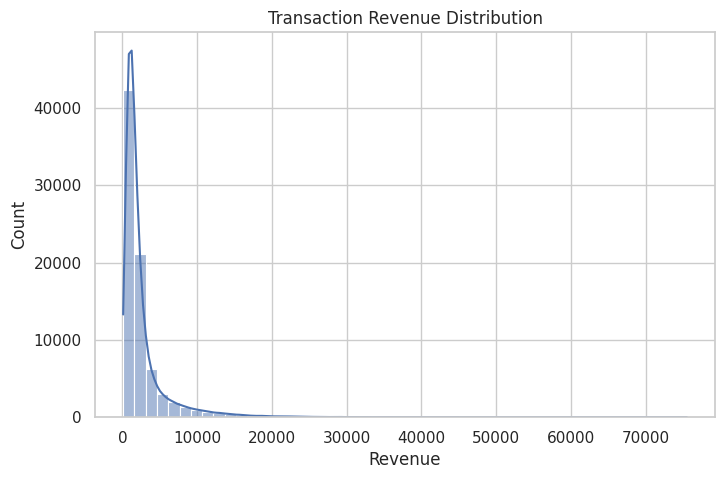

In [8]:
print(df.describe())

plt.figure(figsize=(8, 5))
sns.histplot(df["Revenue"], bins=50, kde=True)
plt.title("Transaction Revenue Distribution")
plt.show()


In [11]:
analysis_date = df["Transaction_Date"].max().normalize() + pd.Timedelta(days=1)

rfm = df.groupby("Customer_ID").agg(
    Recency=("Transaction_Date", lambda x: (analysis_date - x.max().normalize()).days),
    Frequency=("Transaction_ID", "nunique"),
    Monetary=("Revenue", "sum")
)

print("RFM Dataset:")
display(rfm.head())
print(rfm.describe())

RFM Dataset:


,Recency,Frequency,Monetary
Customer_ID,,,
CUST00001,9,10,18172.28
CUST00002,25,15,32469.82
CUST00003,146,8,71678.01
CUST00004,28,7,4678.27
CUST00005,177,1,3410.57


            Recency     Frequency       Monetary
count  11841.000000  11841.000000   11841.000000
mean      66.028376      6.756186   17720.441259
std       63.649700      4.183412   24257.468488
min        1.000000      1.000000     100.000000
25%       18.000000      4.000000    4365.640000
50%       46.000000      6.000000    8446.800000
75%       96.000000      9.000000   19982.650000
max      365.000000     27.000000  220233.910000


In [12]:
rfm_log = np.log1p(rfm)


In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)


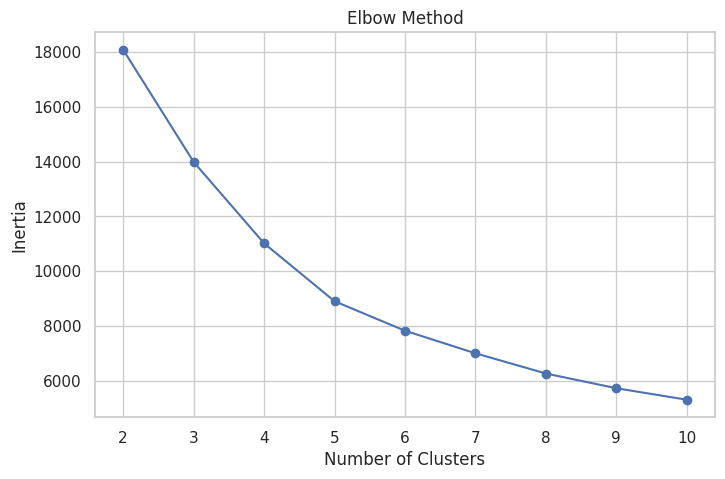

In [14]:
inertias = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()


,K,Silhouette Score
0,2,0.413343
1,3,0.306980
2,4,0.319737
3,5,0.313934
4,6,0.287656
5,7,0.295741
6,8,0.301358
7,9,0.297766
8,10,0.291676


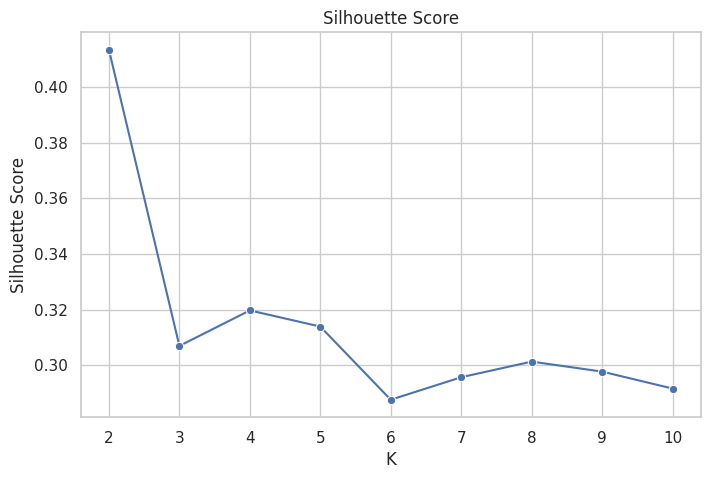

In [15]:
silhouette_results = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(
        X_scaled, labels,
        sample_size=min(5000, len(X_scaled)),
        random_state=42
    )
    silhouette_results.append((k, score))

silhouette_df = pd.DataFrame(silhouette_results, columns=["K", "Silhouette Score"])
display(silhouette_df)

plt.figure(figsize=(8, 5))
sns.lineplot(data=silhouette_df, x="K", y="Silhouette Score", marker="o")
plt.title("Silhouette Score")
plt.show()


In [16]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means Cluster Counts:")
print(rfm["KMeans_Cluster"].value_counts())


K-Means Cluster Counts:
KMeans_Cluster
3    3772
0    3500
1    2716
2    1853
Name: count, dtype: int64


Explained Variance:
[0.72144926 0.22236956]
Total Variance: 0.9438188182507526


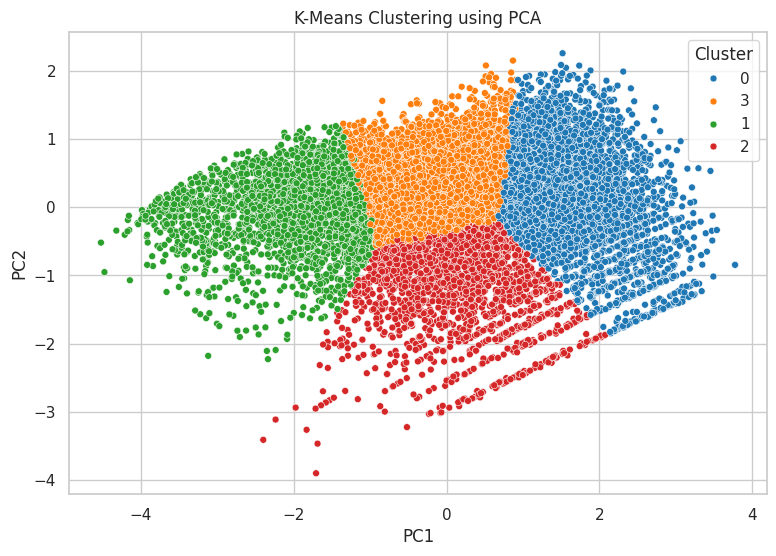

In [17]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Explained Variance:")
print(pca.explained_variance_ratio_)
print("Total Variance:", pca.explained_variance_ratio_.sum())

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"], index=rfm.index)
pca_df["Cluster"] = rfm["KMeans_Cluster"].astype(str)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=25)
plt.title("K-Means Clustering using PCA")
plt.show()


In [18]:
dbscan = DBSCAN(eps=0.7, min_samples=10)
dbscan_labels = dbscan.fit_predict(X_scaled)

rfm["DBSCAN_Cluster"] = dbscan_labels

print("DBSCAN Cluster Counts:")
print(rfm["DBSCAN_Cluster"].value_counts())
print("Number of Clusters:", len(set(dbscan_labels) - {-1}))
print("Noise Points:", (dbscan_labels == -1).sum())


DBSCAN Cluster Counts:
DBSCAN_Cluster
 0    11299
 1      523
 2       17
-1        2
Name: count, dtype: int64
Number of Clusters: 3
Noise Points: 2


In [19]:
dbscan_results = []

for eps in [0.3, 0.5, 0.7, 1.0, 1.2]:
    for min_samples in [5, 10, 15]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        clusters = len(set(labels) - {-1})
        noise_percent = np.mean(labels == -1) * 100
        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": clusters,
            "noise_percent": round(noise_percent, 2)
        })

dbscan_results_df = pd.DataFrame(dbscan_results)
display(dbscan_results_df)


,eps,min_samples,clusters,noise_percent
0,0.3,5,11,0.87
1,0.3,10,10,2.06
2,0.3,15,8,3.23
3,0.5,5,4,0.07
4,0.5,10,4,0.14
5,0.5,15,3,0.24
6,0.7,5,3,0.01
7,0.7,10,3,0.02
8,0.7,15,2,0.16
9,1.0,5,1,0.00


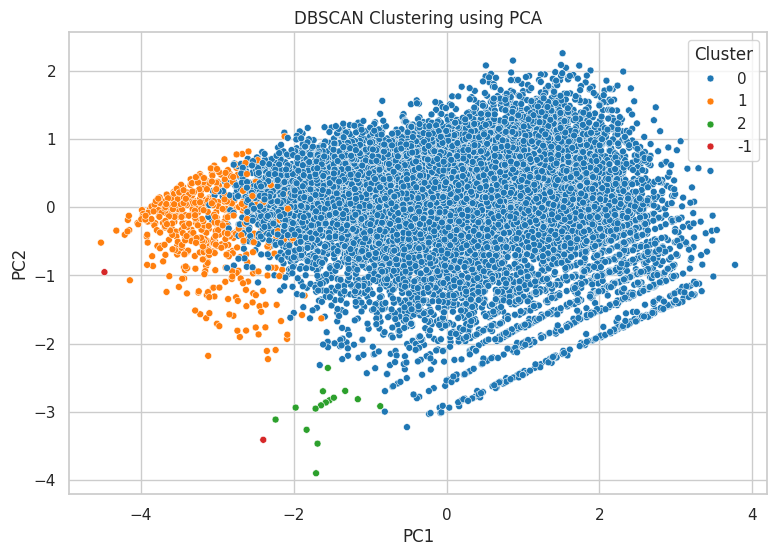

In [20]:
pca_dbscan_df = pca_df.copy()
pca_dbscan_df["Cluster"] = rfm["DBSCAN_Cluster"].astype(str)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_dbscan_df, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=25)
plt.title("DBSCAN Clustering using PCA")
plt.show()


In [21]:
def evaluate_clusters(X, labels):
    labels = np.asarray(labels)
    mask = labels != -1

    X_eval = X[mask]
    labels_eval = labels[mask]

    n_clusters = len(np.unique(labels_eval))

    if n_clusters < 2 or n_clusters >= len(labels_eval):
        score = np.nan
    else:
        score = silhouette_score(
            X_eval, labels_eval,
            sample_size=min(5000, len(X_eval)),
            random_state=42
        )

    return {
        "Clusters": n_clusters,
        "Noise Percentage": np.mean(labels == -1) * 100,
        "Silhouette Score": score
    }


print("K-Means:", evaluate_clusters(X_scaled, rfm["KMeans_Cluster"]))
print("DBSCAN:", evaluate_clusters(X_scaled, rfm["DBSCAN_Cluster"]))


K-Means: {'Clusters': 4, 'Noise Percentage': np.float64(0.0), 'Silhouette Score': np.float64(0.3197368265370142)}
DBSCAN: {'Clusters': 3, 'Noise Percentage': np.float64(0.016890465332319905), 'Silhouette Score': np.float64(0.28917496552690886)}


In [22]:
sample_size = min(5000, len(rfm))
rng = np.random.default_rng(42)
sample_positions = np.sort(rng.choice(len(rfm), size=sample_size, replace=False))

X_tsne_input = X_scaled[sample_positions]
sample_index = rfm.index[sample_positions]

perplexity = min(30, max(5, (sample_size - 1) // 3))

tsne = TSNE(
    n_components=2,
    perplexity=perplexity,
    init="pca",
    learning_rate="auto",
    random_state=42
)

X_tsne = tsne.fit_transform(X_tsne_input)

tsne_df = pd.DataFrame(X_tsne, columns=["TSNE1", "TSNE2"], index=sample_index)
tsne_df["KMeans_Cluster"] = rfm.loc[sample_index, "KMeans_Cluster"].astype(str)
tsne_df["DBSCAN_Cluster"] = rfm.loc[sample_index, "DBSCAN_Cluster"].astype(str)


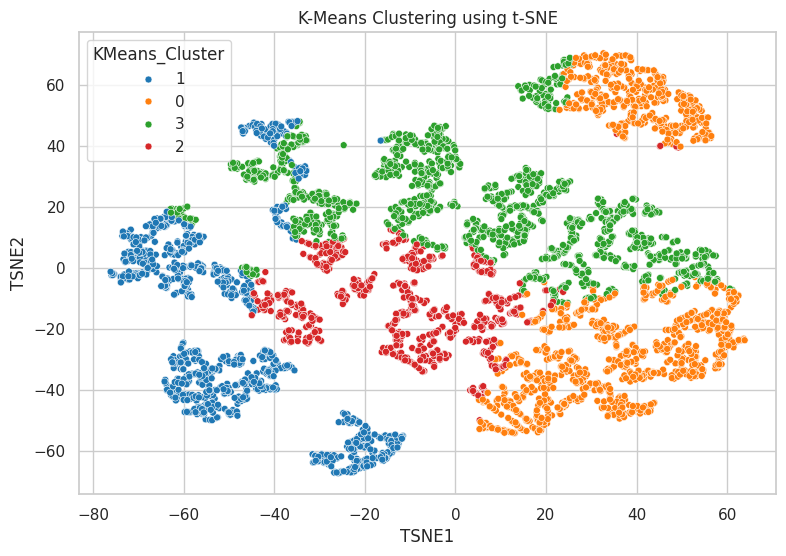

In [24]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=tsne_df, x="TSNE1", y="TSNE2", hue="KMeans_Cluster", palette="tab10", s=25)
plt.title("K-Means Clustering using t-SNE")
plt.show()


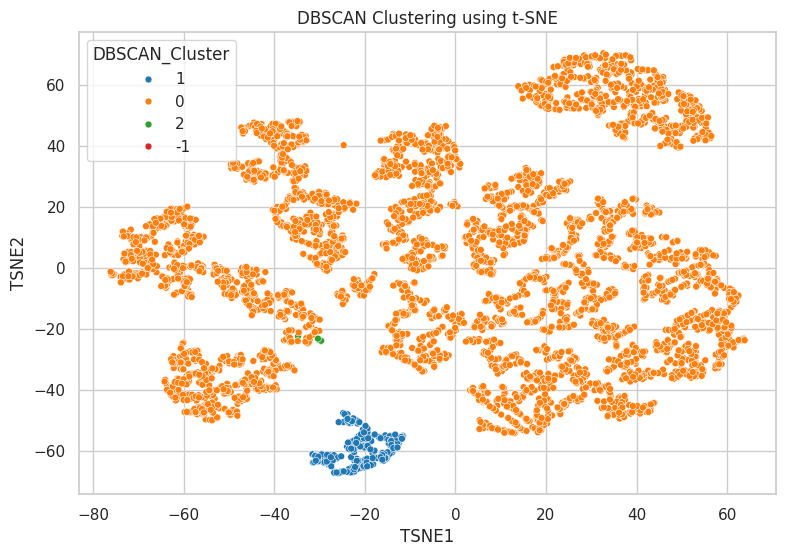

In [25]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=tsne_df, x="TSNE1", y="TSNE2", hue="DBSCAN_Cluster", palette="tab10", s=25)
plt.title("DBSCAN Clustering using t-SNE")
plt.show()


In [26]:
kmeans_profile = rfm.groupby("KMeans_Cluster").agg(
    Customers=("Recency", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Median_Recency=("Recency", "median"),
    Median_Frequency=("Frequency", "median"),
    Median_Monetary=("Monetary", "median")
).round(2)

kmeans_profile["Customer_Percent"] = (100 * kmeans_profile["Customers"] / len(rfm)).round(2)
display(kmeans_profile)


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Recency,Median_Frequency,Median_Monetary,Customer_Percent
KMeans_Cluster,,,,,,,,
0,3500,26.28,11.84,42153.07,20.0,12.0,27293.94,29.56
1,2716,133.91,2.41,2930.24,123.0,2.0,2782.54,22.94
2,1853,13.02,5.10,7070.92,12.0,5.0,6372.59,15.65
3,3772,80.08,5.98,10930.82,71.0,6.0,8337.72,31.86


In [27]:
dbscan_profile = rfm.groupby("DBSCAN_Cluster").agg(
    Customers=("Recency", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Median_Recency=("Recency", "median"),
    Median_Frequency=("Frequency", "median"),
    Median_Monetary=("Monetary", "median")
).round(2)

dbscan_profile["Customer_Percent"] = (100 * dbscan_profile["Customers"] / len(rfm)).round(2)
display(dbscan_profile)


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Recency,Median_Frequency,Median_Monetary,Customer_Percent
DBSCAN_Cluster,,,,,,,,
-1,2,103.00,1.00,187.94,103.0,1.0,187.94,0.02
0,11299,60.51,7.03,18502.87,43.0,6.0,9054.11,95.42
1,523,187.08,1.00,1412.47,170.0,1.0,1037.19,4.42
2,17,4.12,1.00,1453.83,4.0,1.0,1270.63,0.14


In [28]:
overall_medians = rfm[["Recency", "Frequency", "Monetary"]].median()


def draft_persona(row):
    recent = row["Median_Recency"] <= overall_medians["Recency"]
    frequent = row["Median_Frequency"] >= overall_medians["Frequency"]
    high_value = row["Median_Monetary"] >= overall_medians["Monetary"]

    if recent and frequent and high_value:
        return ("Loyal High-Value Customers",
                "VIP rewards, early access and loyalty benefits")
    elif not recent and (frequent or high_value):
        return ("At-Risk Valuable Customers",
                "Personalized win-back campaigns")
    elif recent and not frequent:
        return ("Recent Promising Customers",
                "Second-purchase incentives and recommendations")
    else:
        return ("Low-Engagement Customers",
                "Low-cost email campaigns and relevant bundles")


persona_rows = []

for cluster_id, row in kmeans_profile.iterrows():
    name, action = draft_persona(row)
    persona_rows.append({
        "Cluster": cluster_id,
        "Customer Persona": name,
        "Marketing Strategy": action
    })

persona_table = pd.DataFrame(persona_rows)
display(persona_table)


,Cluster,Customer Persona,Marketing Strategy
0,0,Loyal High-Value Customers,"VIP rewards, early access and loyalty benefits"
1,1,Low-Engagement Customers,Low-cost email campaigns and relevant bundles
2,2,Recent Promising Customers,Second-purchase incentives and recommendations
3,3,At-Risk Valuable Customers,Personalized win-back campaigns


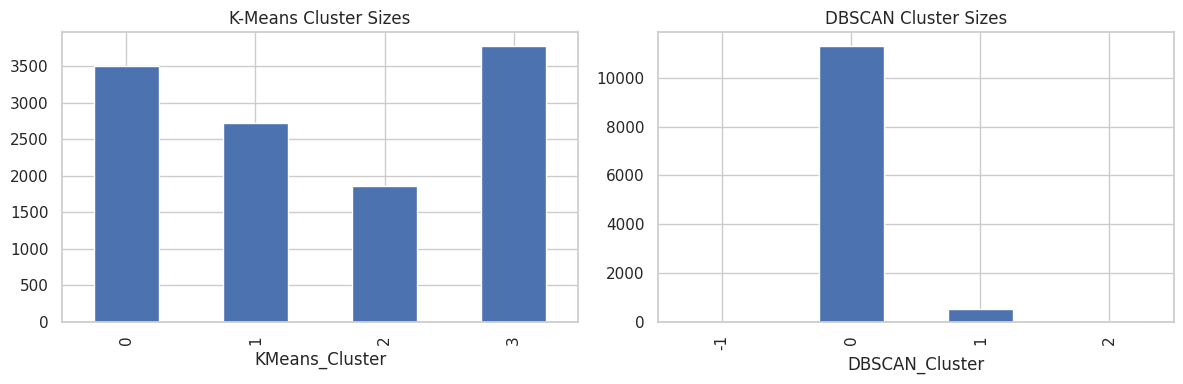

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

rfm["KMeans_Cluster"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], title="K-Means Cluster Sizes")

rfm["DBSCAN_Cluster"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1], title="DBSCAN Cluster Sizes")

plt.tight_layout()
plt.show()


In [30]:
rfm.to_csv("customer_segments.csv")
kmeans_profile.to_csv("kmeans_cluster_profile.csv")
dbscan_profile.to_csv("dbscan_cluster_profile.csv")
persona_table.to_csv("marketing_personas.csv", index=False)
pca_df.to_csv("pca_visualization.csv")
tsne_df.to_csv("tsne_visualization.csv")

print("All project files exported successfully.")


All project files exported successfully.


In [ ]:
files.download("customer_segments.csv")
files.download("kmeans_cluster_profile.csv")
files.download("dbscan_cluster_profile.csv")
files.download("marketing_personas.csv")
files.download("pca_visualization.csv")
files.download("tsne_visualization.csv")
